# Peng--Yang ABSDE benchmarks

This notebook displays the retained JSON and figures. The affine Example 4.3 uses Hermite degree one; the quadratic Examples 5.3 (I--II) use degree two.

## Complete retraining command

```bash
python -m peng_yang.run_campaign \
  --example all \
  --steps 5 10 20 40 80 160 \
  --seeds 42 43 44 \
  --train-paths 1000000 \
  --grid-test-paths 200000 \
  --reconstruction-test-paths 100000 \
  --subdivisions 8 \
  --device cuda
python -m peng_yang.make_figures --device cuda
```

The default degree is selected from the known closed-form solution.

In [1]:
import json
from pathlib import Path
from IPython.display import Image, Markdown, display

root = Path.cwd().resolve()
while root != root.parent and not (root / 'pyproject.toml').is_file():
    root = root.parent
if not (root / 'pyproject.toml').is_file():
    raise FileNotFoundError('repository root not found')
result_root = root / 'peng_yang' / 'results'
figure_root = root / 'peng_yang' / 'figures'
specs = {
    'Example 4.3': 'example_4_3',
    'Example 5.3 (I)': 'example_5_3_1',
    'Example 5.3 (II)': 'example_5_3_2',
}

## Squared reconstruction errors

The orders are adjacent-grid log--log slopes. The theorem controls these squared errors by $C h$.

In [2]:
for title, slug in specs.items():
    rows = json.loads((result_root / f'{slug}_reconstruction_summary.json').read_text())
    degree = rows[0]['hermite_degree']
    lines = [
        f'### {title} — Hermite degree {degree}',
        '',
        '| $N$ | $h$ | $Y$ squared error | order | $Z$ squared error | order |',
        '|---:|---:|---:|---:|---:|---:|',
    ]
    for row in rows:
        y_order = '--' if row['y_mse_sup_order'] is None else f"{row['y_mse_sup_order']:.3f}"
        z_order = '--' if row['z_mse_integrated_order'] is None else f"{row['z_mse_integrated_order']:.3f}"
        lines.append(
            f"| {row['N']} | {row['h']:.6f} | {row['y_mse_sup_mean']:.6e} | {y_order} | "
            f"{row['z_mse_integrated_mean']:.6e} | {z_order} |"
        )
    display(Markdown('\n'.join(lines)))

### Example 4.3 — Hermite degree 1

| $N$ | $h$ | $Y$ squared error | order | $Z$ squared error | order |
|---:|---:|---:|---:|---:|---:|
| 5 | 0.200000 | 1.896009e-01 | -- | 1.585858e-02 | -- |
| 10 | 0.100000 | 9.199574e-02 | 1.043 | 3.965135e-03 | 2.000 |
| 20 | 0.050000 | 4.476589e-02 | 1.039 | 9.949463e-04 | 1.995 |
| 40 | 0.025000 | 2.209026e-02 | 1.019 | 2.446177e-04 | 2.024 |
| 80 | 0.012500 | 1.104906e-02 | 0.999 | 6.130163e-05 | 1.997 |
| 160 | 0.006250 | 5.498391e-03 | 1.007 | 1.735951e-05 | 1.820 |

### Example 5.3 (I) — Hermite degree 2

| $N$ | $h$ | $Y$ squared error | order | $Z$ squared error | order |
|---:|---:|---:|---:|---:|---:|
| 5 | 0.200000 | 7.295776e-01 | -- | 3.490106e-01 | -- |
| 10 | 0.100000 | 3.602564e-01 | 1.018 | 1.747387e-01 | 0.998 |
| 20 | 0.050000 | 1.783121e-01 | 1.015 | 8.749697e-02 | 0.998 |
| 40 | 0.025000 | 8.895071e-02 | 1.003 | 4.379900e-02 | 0.998 |
| 80 | 0.012500 | 4.407175e-02 | 1.013 | 2.192638e-02 | 0.998 |
| 160 | 0.006250 | 2.183575e-02 | 1.013 | 1.099885e-02 | 0.995 |

### Example 5.3 (II) — Hermite degree 2

| $N$ | $h$ | $Y$ squared error | order | $Z$ squared error | order |
|---:|---:|---:|---:|---:|---:|
| 5 | 0.200000 | 1.167324e+01 | -- | 5.584170e+00 | -- |
| 10 | 0.100000 | 5.764103e+00 | 1.018 | 2.795819e+00 | 0.998 |
| 20 | 0.050000 | 2.852994e+00 | 1.015 | 1.399952e+00 | 0.998 |
| 40 | 0.025000 | 1.423211e+00 | 1.003 | 7.007840e-01 | 0.998 |
| 80 | 0.012500 | 7.051480e-01 | 1.013 | 3.508221e-01 | 0.998 |
| 160 | 0.006250 | 3.493719e-01 | 1.013 | 1.759816e-01 | 0.995 |

## Regenerated paper figures

### Example 4.3: quantiles of $Y$ and $Z$

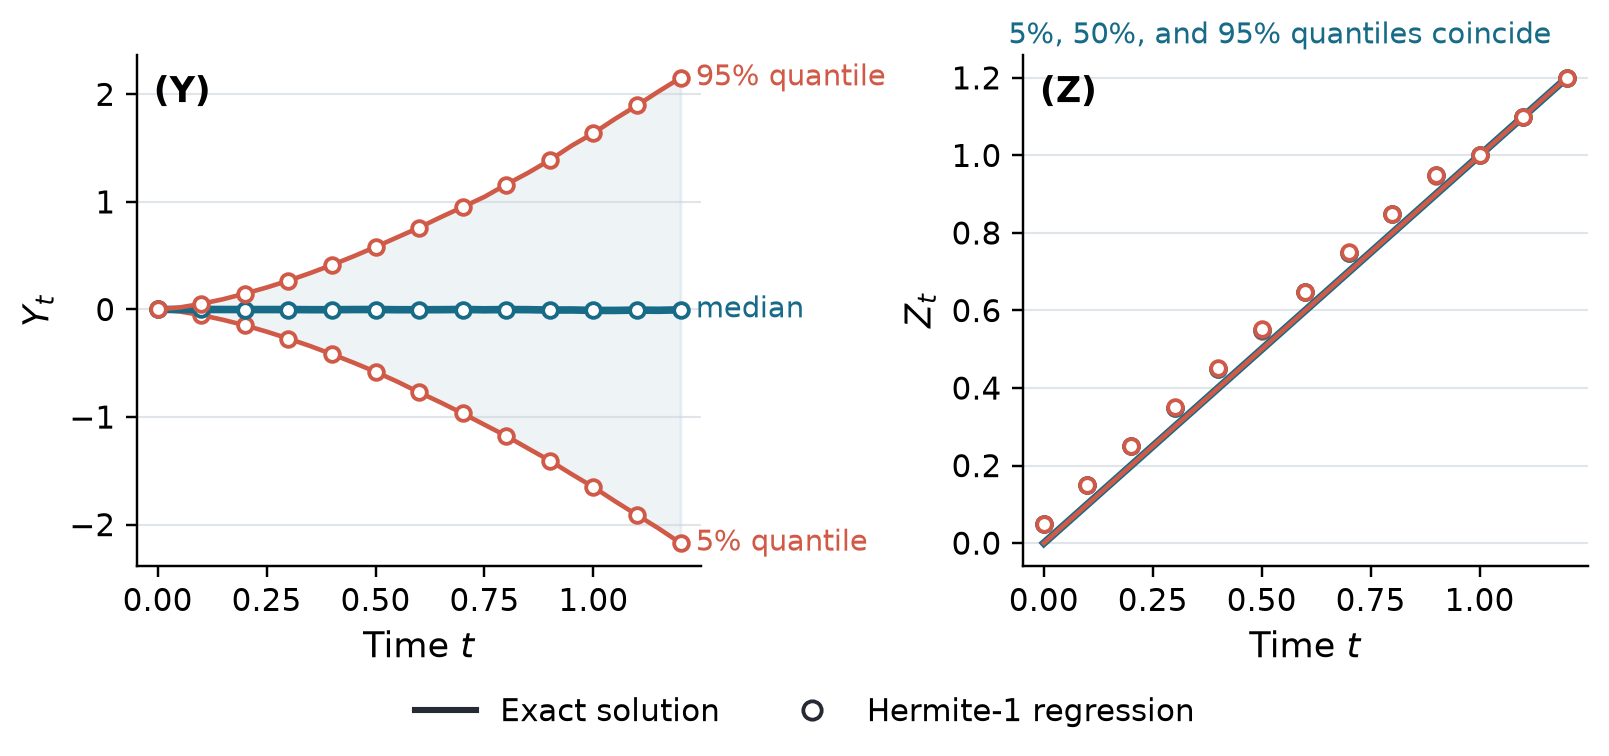

### Example 4.3: squared reconstruction errors

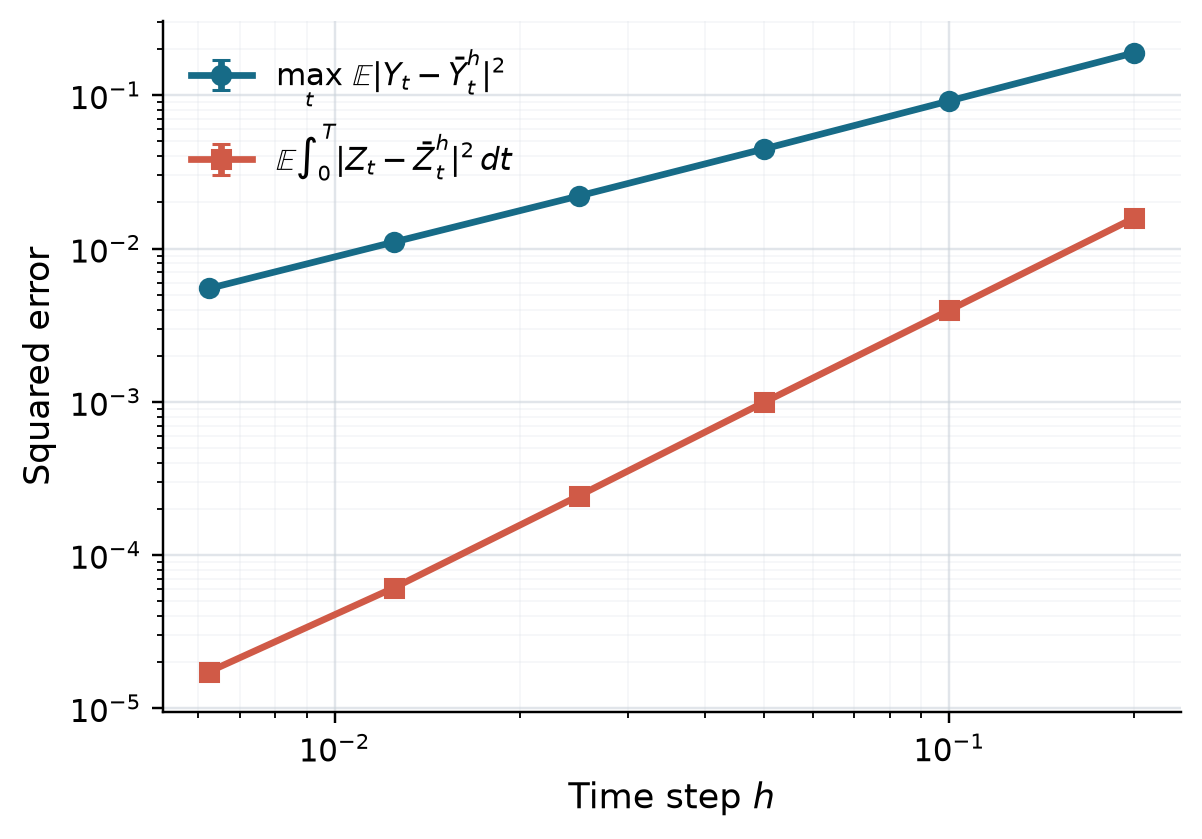

### Example 5.3 (I): quantiles of $Y$ and $Z$

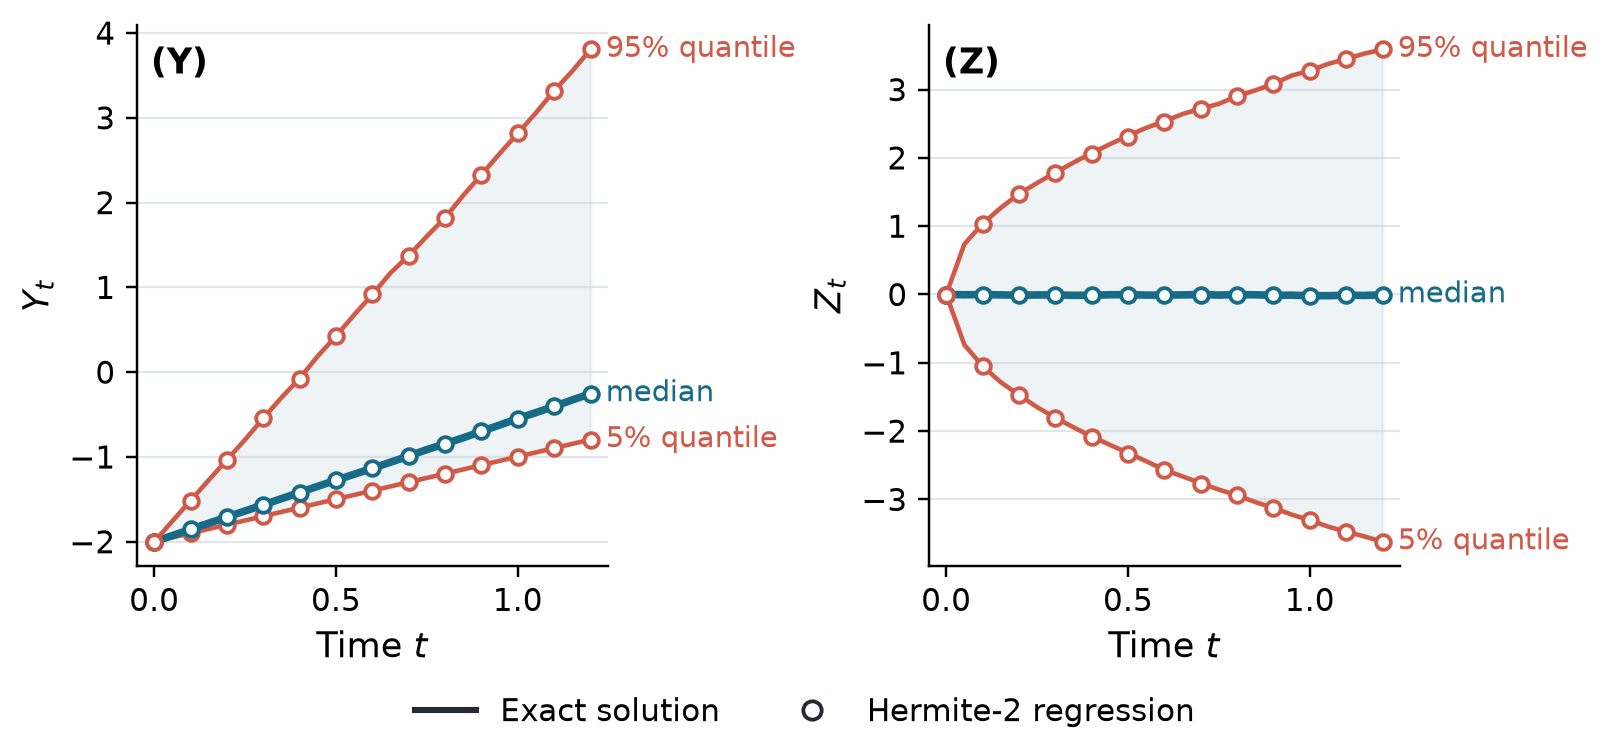

### Example 5.3 (I): squared reconstruction errors

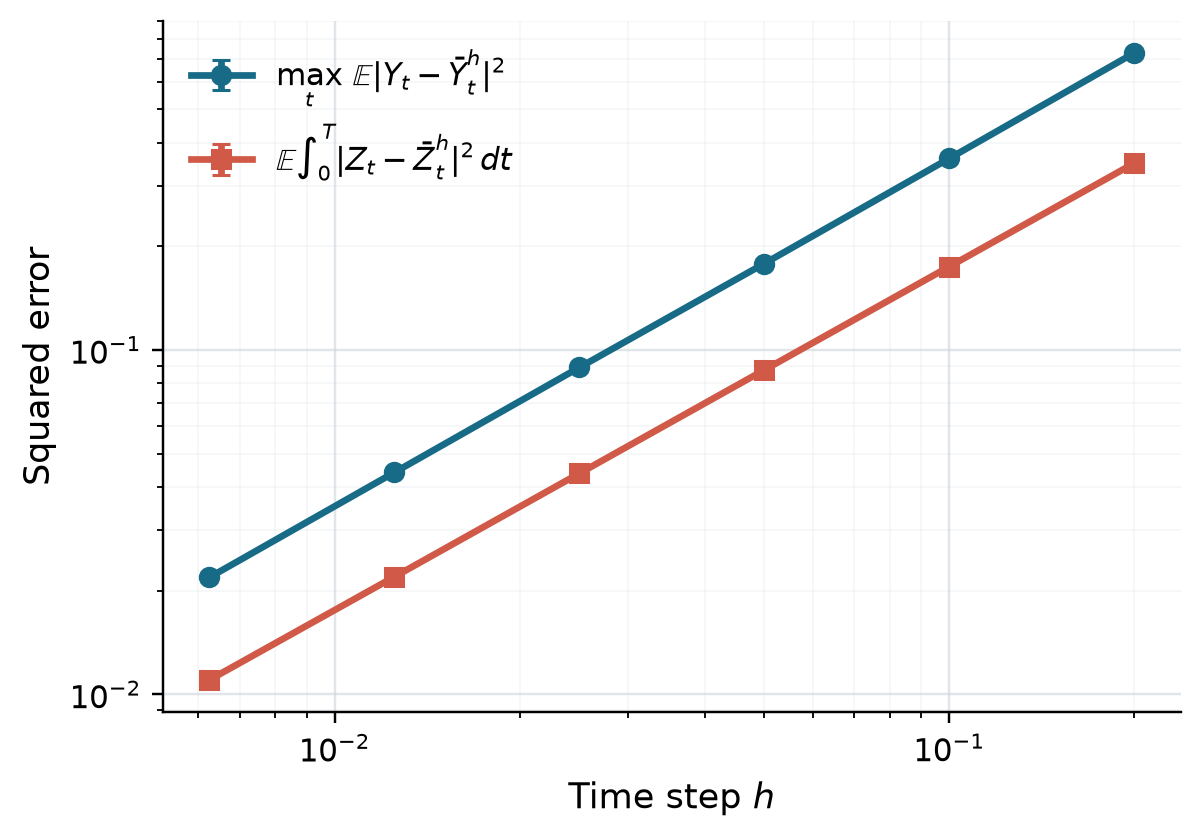

### Example 5.3 (II): quantiles of $Y$ and $Z$

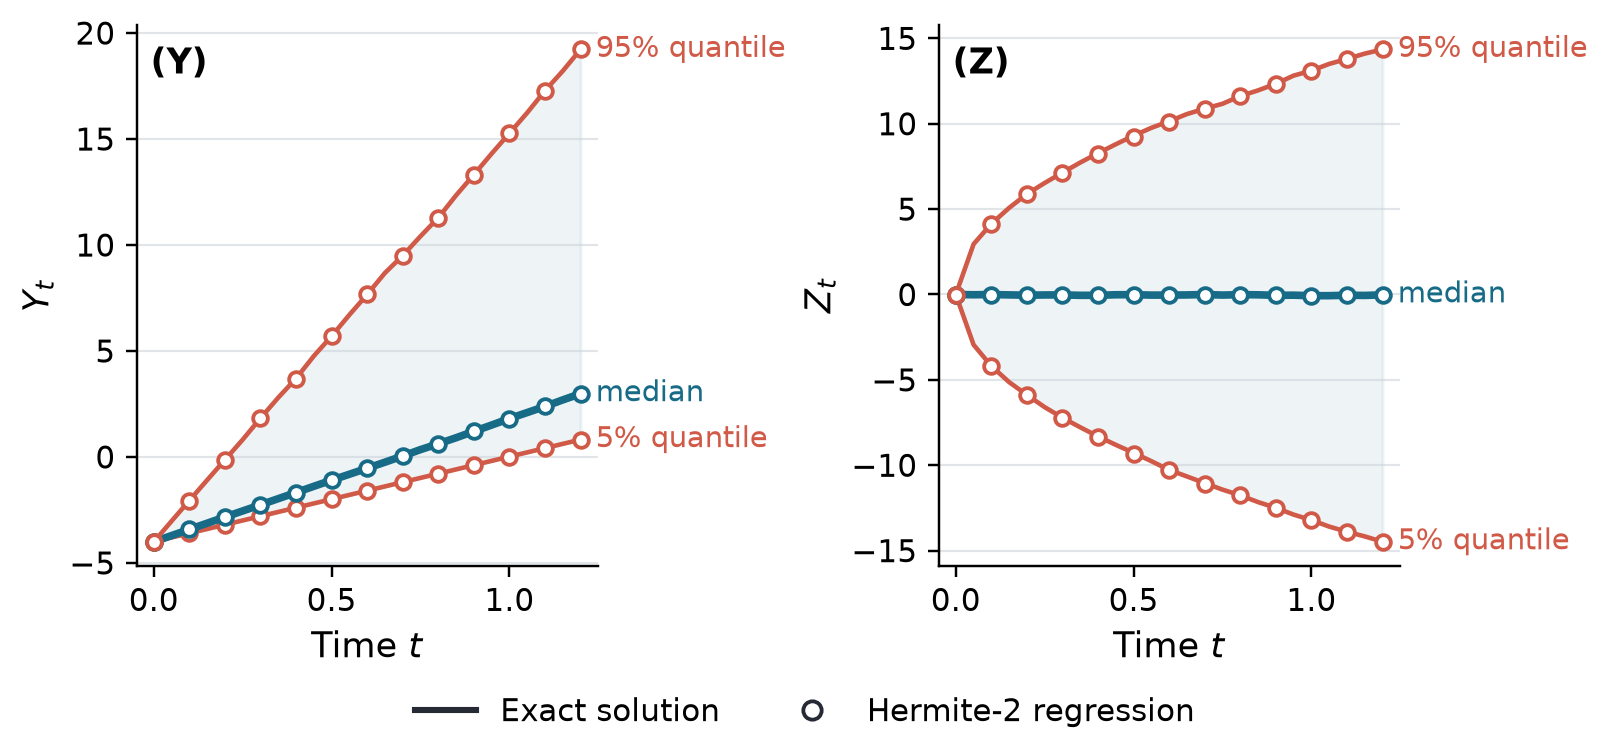

### Example 5.3 (II): squared reconstruction errors

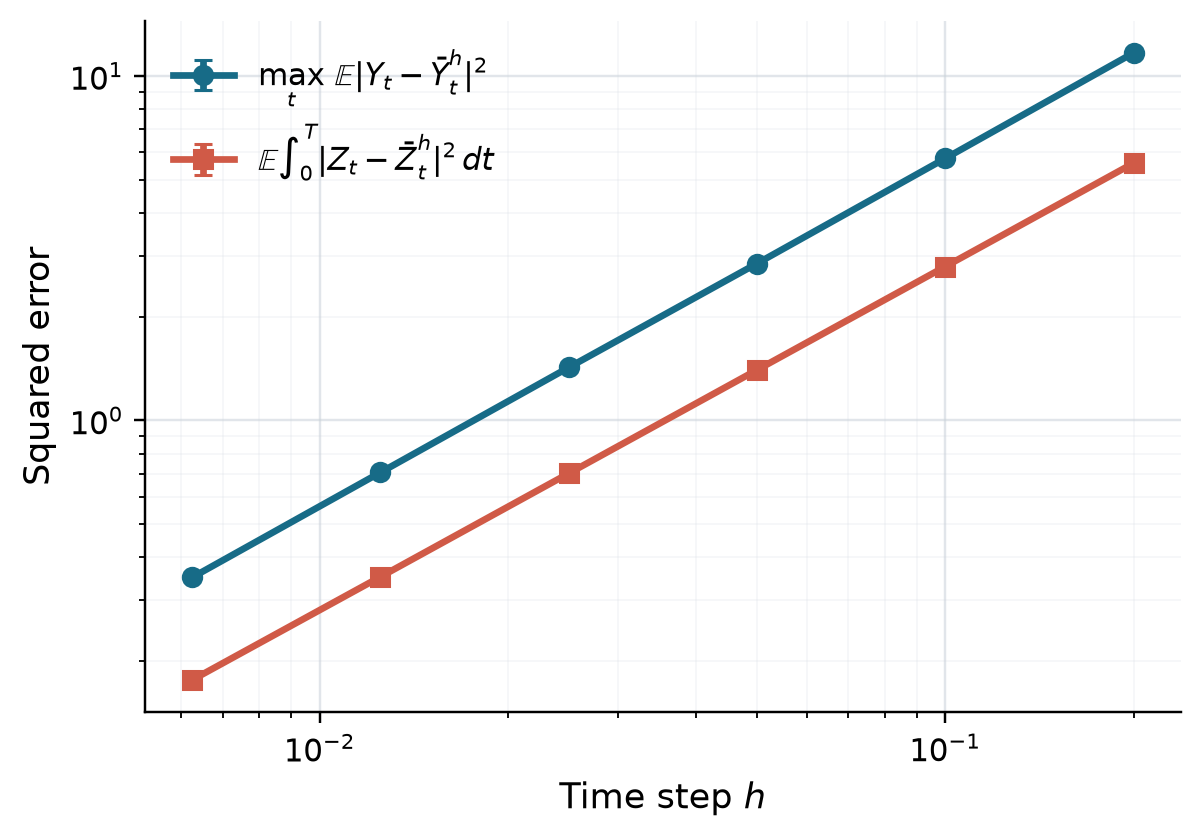

In [3]:
for title, slug in specs.items():
    display(Markdown(f'### {title}: quantiles of $Y$ and $Z$'))
    display(Image(filename=figure_root / f'{slug}_y_z_quantiles.png'))
    display(Markdown(f'### {title}: squared reconstruction errors'))
    display(Image(filename=figure_root / f'{slug}_theorem_5_5.png'))